# Лабораторна робота №1. Отримання та підготовка Time Series
Варіант 7 (ІІ + ІІІ рівень): похибка — рівномірний і нормальний закони, тренд — квадратичний і лінійний. Реальні дані — 3 показники курсу USD Ощадбанку.

## 1. Моделі випадкової величини
Функції генерують вибірку за рівномірним і нормальним законом, рахують мат. сподівання, дисперсію, СКВ і будують гістограму.

In [1]:
def random_uniform (a, b, iter):
    S = np.zeros((iter))
    for i in range(iter):
        S[i] = np.random.uniform(a, b)
    mS = np.mean(S)
    dS = np.var(S)
    scvS = mt.sqrt(dS)
    print('------- Cтатистичні характеристики РІВНОМІРНОГО закону розподілу ВВ -----')
    print('матиматичне сподівання ВВ=', mS)
    print('дисперсія ВВ =', dS)
    print('СКВ ВВ=', scvS)
    print('--------------------------------------------------------------------------')
    plt.hist(S, bins=20, facecolor="blue", alpha=0.5, edgecolor="black")
    plt.show()
    return S

In [2]:
def rando_norm (dm, dsig, iter):
    S = np.random.normal(dm, dsig, iter)
    mS = np.mean(S)
    dS = np.var(S)
    scvS = mt.sqrt(dS)
    print('------- Статистичні характеристики НОРМАЛЬНОГО закону розподілу ВВ -----')
    print('Матиматичне сподівання ВВ=', mS)
    print('Дисперсія ВВ =', dS)
    print('СКВ ВВ=', scvS)

    print('------------------------------------------------------------------------')
    plt.hist(S, bins=8, facecolor="blue", alpha=0.5, edgecolor="black")
    plt.show()
    return S

Генеруємо вибірки обсягом N = 1000: нормальний закон N(0, 1) і рівномірний U(−10, 10).

------- Статистичні характеристики НОРМАЛЬНОГО закону розподілу ВВ -----
Матиматичне сподівання ВВ= 0.005790172274570612
Дисперсія ВВ = 1.0655936468073046
СКВ ВВ= 1.0322759547753229
------------------------------------------------------------------------


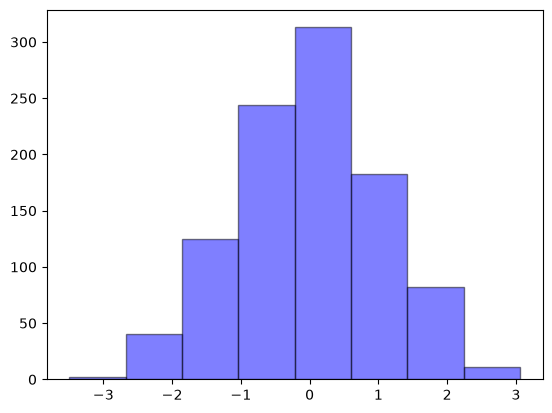

------- Cтатистичні характеристики РІВНОМІРНОГО закону розподілу ВВ -----
матиматичне сподівання ВВ= 0.22177435340272061
дисперсія ВВ = 33.89477560062409
СКВ ВВ= 5.821921985102866
--------------------------------------------------------------------------


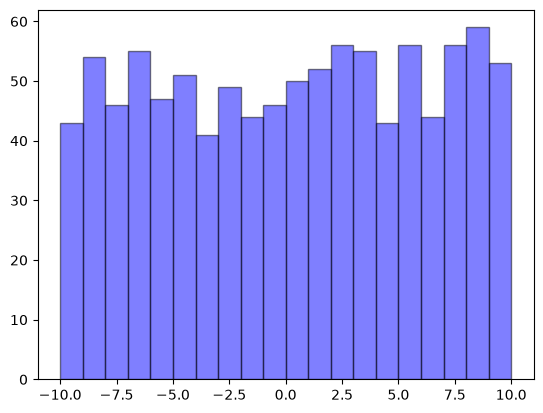

In [3]:
import numpy as np
import math as mt
import matplotlib.pyplot as plt

N = 1000 #sample size
x = range(N)

normal_sample = rando_norm(0, 1, N)
uniform_sample = random_uniform(-10, 10, N)

## 2. Моделі тренду (ідеальний процес)
Квадратичний тренд y = 0.000005·t² і лінійний y = 0.06·t − 2.

In [4]:
def square_model(n):
    S0=np.zeros(n)
    for i in range(n):
        S0[i]=(0.000005*i*i)
    return S0
square_y = square_model(N)

In [5]:
def linear_model(k, b, n):
    S0=np.zeros(n)
    for i in range(n):
        S0[i] = k * i + b
    return S0
k = 0.06
b = -2
linear_y = linear_model(k, b, N)

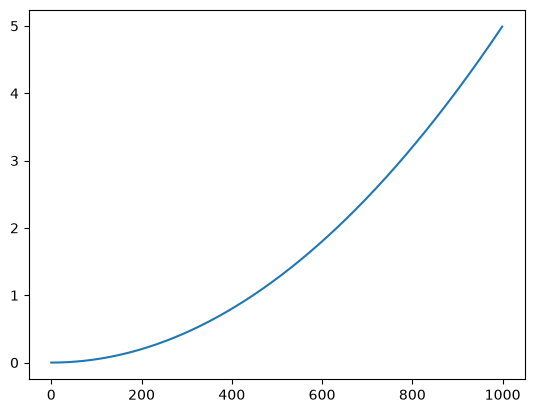

In [6]:
plt.plot(x, square_y)
plt.show()

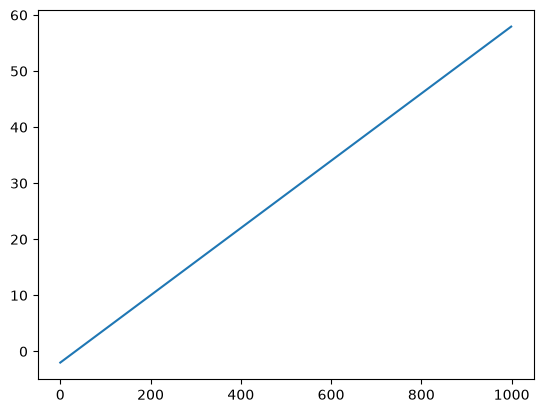

In [7]:
plt.plot(x, linear_y)
plt.show()

## 3. Адитивні моделі: тренд + похибка
Комбінуємо обидва тренди з обома законами похибки й отримуємо 4 вибірки.

In [8]:
additive_square_normal = [x + y for x, y in zip(normal_sample, square_y)]
additive_square_uniform = [x + y for x, y in zip(uniform_sample, square_y)]
additive_linear_normal = [x + y for x, y in zip(normal_sample, linear_y)]
additive_linear_uniform = [x + y for x, y in zip(linear_y, uniform_sample)]



## 4. Статистичні характеристики адитивних моделей
Для кожної моделі будуємо графік разом з ідеальним трендом і виводимо числові характеристики.

In [9]:
def plot_additive(additive_model, ideal_model):
    plt.plot(x, additive_model)
    plt.plot(x, ideal_model)
    plt.show()
    mean = np.mean(additive_model)
    std = np.std(additive_model)
    var = np.var(additive_model)
    print("-----------Характеристики:------------")
    print("Мат. сподівання: " + str(mean))
    print("Дисперсія: " + str(var))
    print("Середньоквадратичне відхилення: " + str(std))
    print("---------------------------|-----------")
    

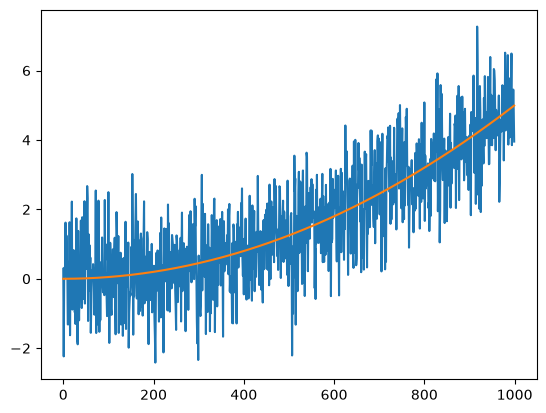

-----------Характеристики:------------
Мат. сподівання: 1.669957672274571
Дисперсія: 3.2387316820694414
Середньоквадратичне відхилення: 1.799647654978452
---------------------------|-----------


In [10]:
plot_additive(additive_square_normal, square_y)

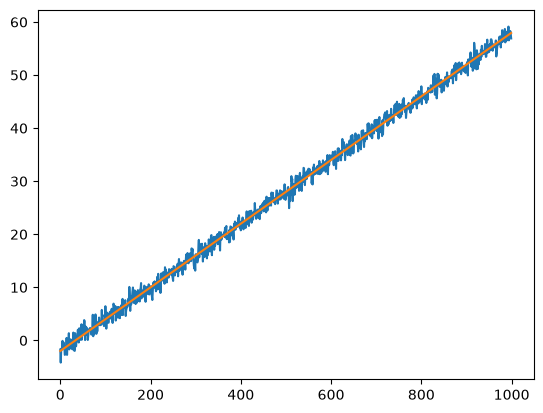

-----------Характеристики:------------
Мат. сподівання: 27.975790172274568
Дисперсія: 300.56319947103145
Середньоквадратичне відхилення: 17.336758620660074
---------------------------|-----------


In [11]:
plot_additive(additive_linear_normal, linear_y)

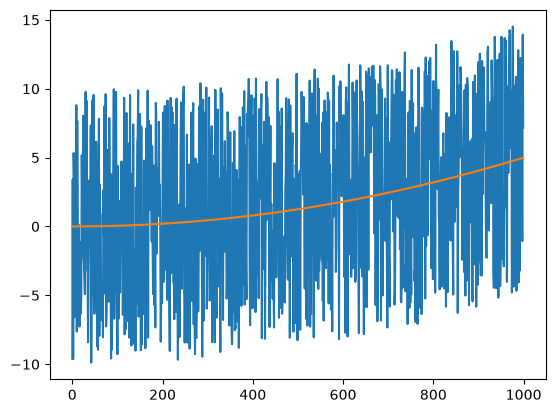

-----------Характеристики:------------
Мат. сподівання: 1.8859418534027206
Дисперсія: 36.758651700274356
Середньоквадратичне відхилення: 6.06289136470994
---------------------------|-----------


In [12]:
plot_additive(additive_square_uniform, square_y)

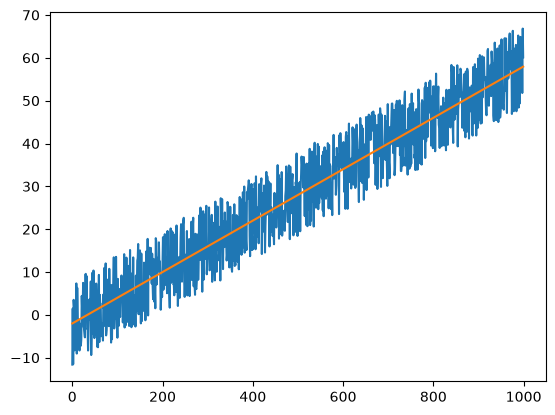

-----------Характеристики:------------
Мат. сподівання: 28.19177435340272
Дисперсія: 344.68576082794056
Середньоквадратичне відхилення: 18.565714659768435
---------------------------|-----------


In [13]:
plot_additive(additive_linear_uniform, linear_y)

## 5. Реальні дані: курс USD Ощадбанку
Аналізуємо три показники: купівля, продаж, курс НБУ.

In [14]:
import pandas as pd

df = pd.read_csv("Oschadbank-_USD_.csv")

In [15]:
df.head()

,Дата,Час,Купівля,Продаж,КурсНбу
0,08.02.2022,08:25:07,27.70,28.10,27.9998
1,09.02.2022,07:43:56,27.75,28.12,27.9619
2,10.02.2022,08:33:20,27.78,28.12,27.9795
3,11.02.2022,00:39:19,27.75,28.10,27.8756
4,14.02.2022,00:00:06,27.85,28.20,28.0346


In [16]:
def get_stats(series : pd.Series):
    mean = np.mean(series)
    std = np.std(series)
    var = np.var(series)
    plt.hist(series, edgecolor="black")
    plt.show()
    print("-----------Характеристики:------------")
    print("Мат. сподівання: " + str(mean))
    print("Дисперсія: " + str(var))
    print("Середньоквадратичне відхилення: " + str(std))
    print("---------------------------|-----------")
    

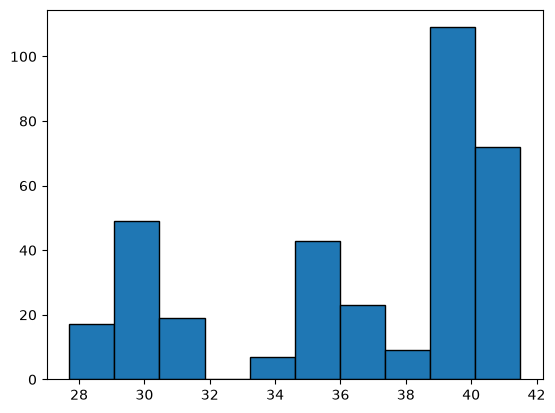

-----------Характеристики:------------
Мат. сподівання: 36.48076436781609
Дисперсія: 19.079833612293566
Середньоквадратичне відхилення: 4.368046887602463
---------------------------|-----------


In [17]:
get_stats(df["Купівля"])

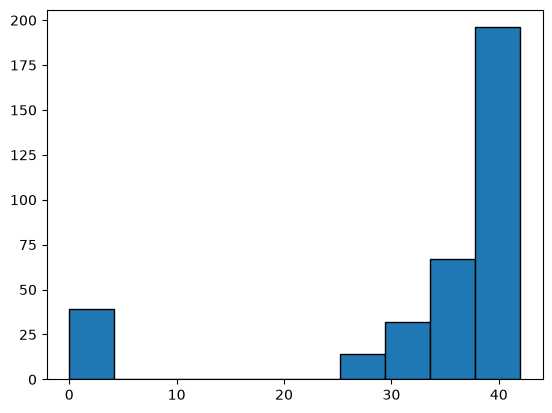

-----------Характеристики:------------
Мат. сподівання: 33.861781609195404
Дисперсія: 156.4326249867882
Середньоквадратичне відхилення: 12.50730286619734
---------------------------|-----------


In [18]:
get_stats(df["Продаж"])

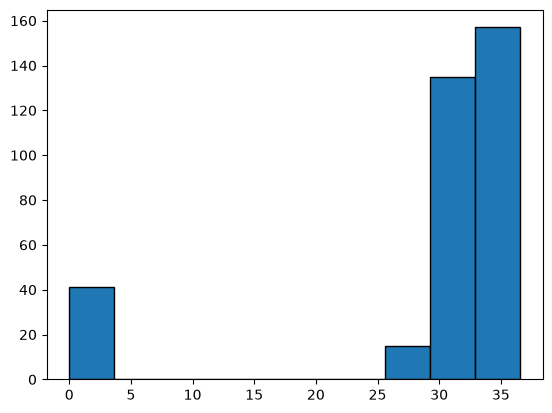

-----------Характеристики:------------
Мат. сподівання: 29.06374942528736
Дисперсія: 124.97695564347669
Середньоквадратичне відхилення: 11.179309265043019
---------------------------|-----------


In [19]:
get_stats(df["КурсНбу"])

### Аналіз результатів (завдання І–ІІ рівня)
Характеристики згенерованих похибок близькі до теоретичних: для N(0, 1) отримано m ≈ 0.006 і D ≈ 1.07, для U(−10, 10) — m ≈ 0.22 і D ≈ 33.9 (теоретично 0 і 33.3), тобто генератори працюють коректно. В адитивних моделях дисперсію визначає переважно тренд: для лінійного тренду вона ≈ 300, а шум додає лише 1–33 одиниці. Гістограми адитивних вибірок уже не повторюють закон похибки, бо тренд «розтягує» розподіл. У даних Ощадбанку стовпці «Продаж» і «КурсНбу» містять ~40 нульових значень (фактично пропуски), через що їхня дисперсія завищена (156 і 125 проти 19 у «Купівля»), тому перед аналізом такі значення слід відкидати.

## 6. Завдання ІІІ рівня: парсинг індексу інфляції
Парсимо таблицю індексу споживчих цін (% до попереднього місяця) з index.minfin.com.ua за допомогою requests + BeautifulSoup.

In [20]:
import os
import requests
from bs4 import BeautifulSoup
import warnings
warnings.filterwarnings('ignore')


# =====================================================================================
# 1. ФУНКЦІЯ ПАРСИНГУ САЙТУ  https://index.minfin.com.ua/ua/economy/index/inflation/
# =====================================================================================
def parse_inflation_index(url, local_fallback_csv=None):
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                       '(KHTML, like Gecko) Chrome/116.0.0.0 Safari/537.36'
    }
    months_ua = ['січень', 'лютий', 'березень', 'квітень', 'травень', 'червень',
                 'липень', 'серпень', 'вересень', 'жовтень', 'листопад', 'грудень']

    dates, values = [], []
    try:
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()
        print('HTTP статус відповіді:', response.status_code)

        soup = BeautifulSoup(response.text, 'html.parser')
        table = soup.find('table')
        if table is None:
            raise ValueError('На сторінці не знайдено жодної html-таблиці (<table>)')

        rows_html = table.find_all('tr')
        header_cells = [c.get_text(strip=True) for c in rows_html[0].find_all(['th', 'td'])]
        body = []
        for tr in rows_html[1:]:
            cells = [c.get_text(strip=True) for c in tr.find_all(['th', 'td'])]
            if cells:
                body.append(cells)
        df = pd.DataFrame(body, columns=header_cells[:len(body[0])] if body else header_cells)
        df = df.set_index(df.columns[0])

        for year in df.index:
            for m_idx, month_name in enumerate(months_ua):
                col = [c for c in df.columns if str(c).lower().startswith(month_name[:3])]
                if not col:
                    continue
                val = str(df.loc[year, col[0]]).replace(',', '.').strip()
                if val in ('', '-', 'nan', '--', '-.--'):
                    continue
                try:
                    v = float(val)
                except ValueError:
                    continue
                dates.append(f'{int(year)}-{m_idx + 1:02d}')
                values.append(v)

        
        print(f'Парсинг виконано успішно: отримано {len(values)} значень')
        print('Джерело даних:', url)

    except Exception as e:
        print(f'[Увага] Пряме мережеве звернення до сайту не вдалося ({e}).')
        return
        

    return dates, np.array(values, dtype=float)



Збереження результатів парсингу у CSV-файл.

In [21]:
#ЗБЕРЕЖЕННЯ РЕЗУЛЬТАТІВ ПАРСИНГУ У ФАЙЛ 

def save_parsing_result(dates, values, filename):
    df = pd.DataFrame({'date': dates, 'cpi_mom_percent': values})
    df.to_csv(filename, index=False, encoding='utf-8-sig')
    print('Результати парсингу збережено у файл:', filename)
    return df


Статистичні характеристики вибірки: середнє, медіана, дисперсія, СКВ, min/max і гістограма.

In [22]:

# СТАТИСТИЧНІ ХАРАКТЕРИСТИКИ ВИБІРКИ + ГІСТОГРАМА

def Stat_characteristics(SL, Text):
    mS = np.median(SL)
    mean_S = np.mean(SL)
    dS = np.var(SL)
    scvS = mt.sqrt(dS)
    print('------------', Text, '-------------')
    print('кількість елементів вибірки =', len(SL))
    print('середнє арифметичне =', mean_S)
    print('медіана =', mS)
    print('дисперсія =', dS)
    print('СКВ =', scvS)
    print('мінімум / максимум =', np.min(SL), '/', np.max(SL))
    print('-----------------------------------------------------')

    plt.figure(figsize=(7, 4.5))
    plt.hist(SL, bins=20, facecolor="royalblue", alpha=0.7, edgecolor='black')
    plt.title('Гістограма закону розподілу: ' + Text)
    plt.xlabel('Значення, %')
    plt.ylabel('Частота')
    plt.tight_layout()
    plt.show()

    return {'mean': mean_S, 'median': mS, 'var': dS, 'std': scvS,
            'min': np.min(SL), 'max': np.max(SL), 'n': len(SL)}


Допоміжні функції: тренд за МНК, коефіцієнт детермінації R², синтез моделі (тренд + нормальний шум) і її верифікація порівнянням з реальними даними.

In [23]:
# =====================================================================================
# 3. МНК - ОЦІНКА ДИНАМІКИ ТРЕНДУ
# =====================================================================================
def MNK_Trend(S0, degree=1):
    n = len(S0)
    Yin = np.zeros((n, 1))
    F = np.ones((n, degree + 1))
    for i in range(n):
        Yin[i, 0] = float(S0[i])
        for p in range(1, degree + 1):
            F[i, p] = float(i) ** p
    FT = F.T
    C = np.linalg.inv(FT.dot(F)).dot(FT).dot(Yin)
    Yout = F.dot(C)

    eq = 'y(t) = ' + ' + '.join(
        [f'{C[p, 0]:.6f}*t^{p}' if p > 0 else f'{C[p, 0]:.6f}' for p in range(degree + 1)])
    print('Регресійна модель тренду (МНК):')
    print(eq)
    return Yout.flatten(), C.flatten()


def r2_score(SL, Yout, Text=''):
    numerator = np.sum((SL - Yout) ** 2)
    denominator = np.sum((SL - np.mean(SL)) ** 2)
    R2 = 1 - (numerator / denominator)
    print('------------', Text, '-------------')
    print('кількість елементів вибірки =', len(SL))
    print('Коефіцієнт детермінації R2 =', R2)
    return R2


def Plot_series(series_list, labels, title, ylabel):
    plt.figure(figsize=(11, 5))
    for s, lab in zip(series_list, labels):
        plt.plot(s, label=lab, linewidth=1.4)
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xlabel('t (місяці)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()



#  СИНТЕЗ ТА ВЕРИФІКАЦІЯ МОДЕЛІ ДАНИХ, АНАЛОГІЧНОЇ РЕАЛЬНИМ ДАНИМ

def synthesize_model(trend, residual_std, n, dm=0.0, seed=42):
    '''Адитивна модель: S_model(t) = trend(t) + N(dm, residual_std).'''
    rng = np.random.default_rng(seed)
    noise = rng.normal(dm, residual_std, n)
    return trend + noise, noise


def verify_model(real_stats, model_stats, real_C, model_C, r2_real, r2_model):
    print('--------------------- ВЕРИФІКАЦІЯ МОДЕЛІ ---------------------')
    print(f"{'Характеристика':30s}{'Реальні дані':>18s}{'Синтезована модель':>22s}{'Похибка,%':>14s}")
    for name, r, m in [('середнє', real_stats['mean'], model_stats['mean']),
                        ('дисперсія', real_stats['var'], model_stats['var']),
                        ('СКВ', real_stats['std'], model_stats['std'])]:
        err = abs(r - m) / abs(r) * 100 if r != 0 else float('nan')
        print(f'{name:30s}{r:18.4f}{m:22.4f}{err:14.2f}')
    print('-' * 84)
    print('Коефіцієнти лінійного тренду (a0 + a1*t):')
    print(f'  реальні дані:        a0={real_C[0]:.5f}   a1={real_C[1]:.6f}')
    print(f'  синтезована модель:  a0={model_C[0]:.5f}   a1={model_C[1]:.6f}')
    print(f'R2 (реальні дані)      = {r2_real:.4f}')
    print(f'R2 (синтезована модель) = {r2_model:.4f}')
    print('=' * 84)





Запуск усього процесу: парсинг → збереження → тренд → статистики → синтез і верифікація моделі.

-------------------- ПАРСИНГ ТА ЗБЕРЕЖЕННЯ ДАНИХ  --------------------
HTTP статус відповіді: 200
Парсинг виконано успішно: отримано 319 значень
Джерело даних: https://index.minfin.com.ua/ua/economy/index/inflation/
Результати парсингу збережено у файл: inflation_parsed_result.csv
Обсяг отриманої вибірки (кількість місяців): 319

-------------------- ОЦІНКА ДИНАМІКИ ТРЕНДУ --------------------------
Регресійна модель тренду (МНК):
y(t) = 100.941804 + -0.000060*t^1
------------ Якість лінійної моделі тренду реальних даних -------------
кількість елементів вибірки = 319
Коефіцієнт детермінації R2 = 1.5371642884565162e-05


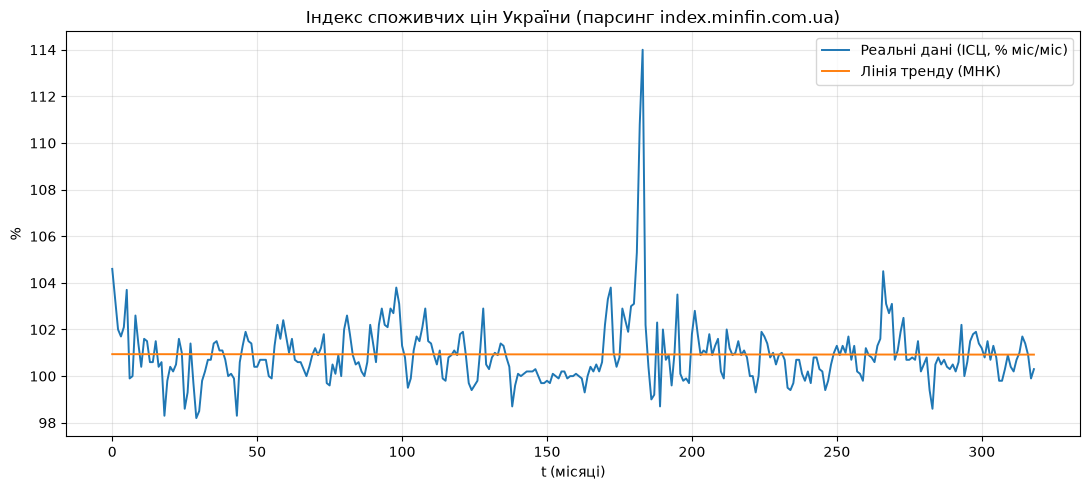


-------------------- СТАТИСТИЧНІ ХАРАКТЕРИСТИКИ РЕАЛЬНИХ ДАНИХ -----------
------------ Реальні дані парсингу (ІСЦ, %) -------------
кількість елементів вибірки = 319
середнє арифметичне = 100.93228840125391
медіана = 100.7
дисперсія = 1.9760420986428984
СКВ = 1.4057176454191995
мінімум / максимум = 98.2 / 114.0
-----------------------------------------------------


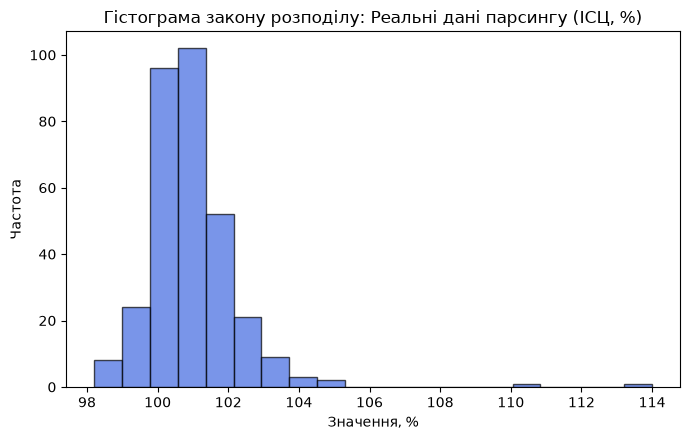

------------ Залишки (реальні дані мінус тренд МНК) -------------
кількість елементів вибірки = 319
середнє арифметичне = 3.118369373241819e-14
медіана = -0.22313143224698706
дисперсія = 1.976011723629433
СКВ = 1.405706841282859
мінімум / максимум = -2.740068832436208 / 13.069147986041315
-----------------------------------------------------


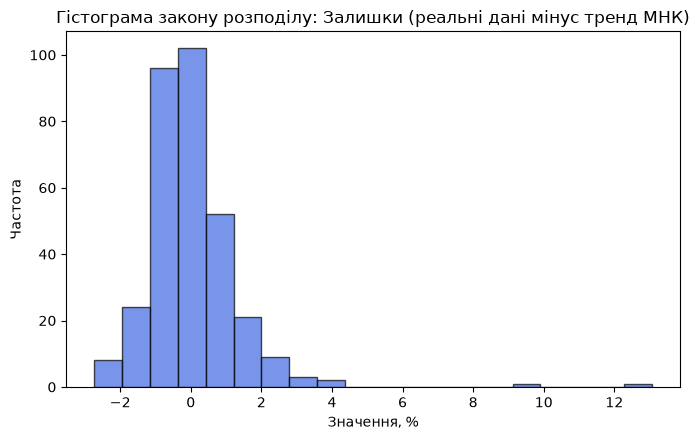


-------------------- СИНТЕЗ ТА ВЕРИФІКАЦІЯ МОДЕЛІ  -----------------------
Регресійна модель тренду (МНК):
y(t) = 100.834271 + 0.000485*t^1
------------ Якість лінійної моделі тренду синтезованих даних -------------
кількість елементів вибірки = 319
Коефіцієнт детермінації R2 = 0.001156397363957784
------------ Синтезована модель (тренд + норм. шум) -------------
кількість елементів вибірки = 319
середнє арифметичне = 100.91140551220656
медіана = 100.86105153471526
дисперсія = 1.7258190226817849
СКВ = 1.3137043132614679
мінімум / максимум = 97.31629924253554 / 105.02952179369042
-----------------------------------------------------


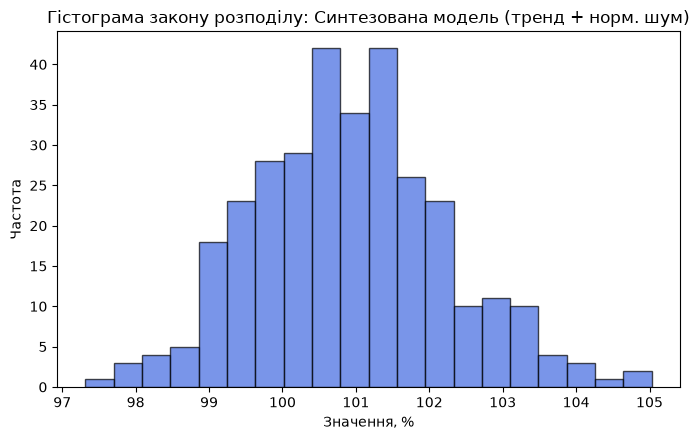

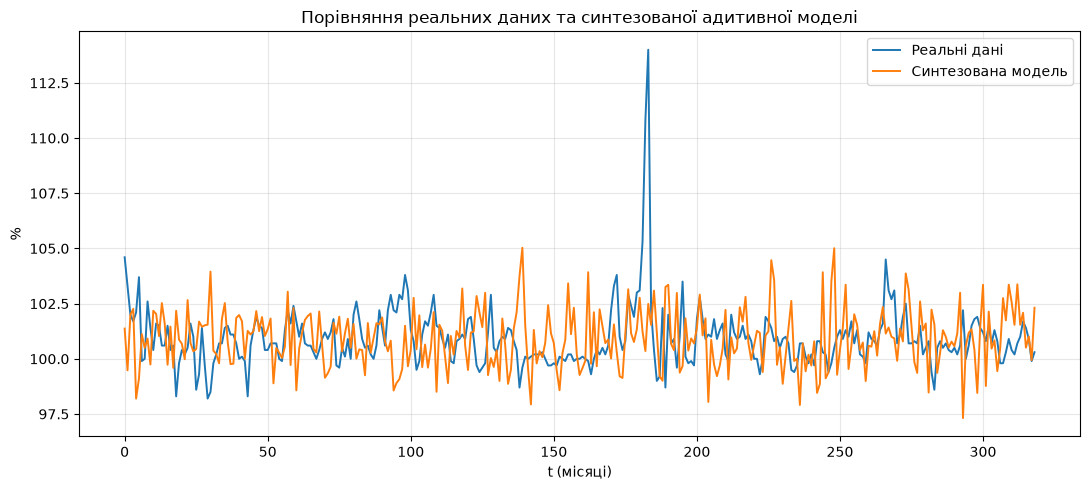

--------------------- ВЕРИФІКАЦІЯ МОДЕЛІ ---------------------
Характеристика                      Реальні дані    Синтезована модель     Похибка,%
середнє                                 100.9323              100.9114          0.02
дисперсія                                 1.9760                1.7258         12.66
СКВ                                       1.4057                1.3137          6.55
------------------------------------------------------------------------------------
Коефіцієнти лінійного тренду (a0 + a1*t):
  реальні дані:        a0=100.94180   a1=-0.000060
  синтезована модель:  a0=100.83427   a1=0.000485
R2 (реальні дані)      = 0.0000
R2 (синтезована модель) = 0.0012


In [24]:
URL = 'https://index.minfin.com.ua/ua/economy/index/inflation/'

SAVED_CSV = 'inflation_parsed_result.csv'  

print("-------------------- ПАРСИНГ ТА ЗБЕРЕЖЕННЯ ДАНИХ  --------------------")
dates, S_real = parse_inflation_index(URL)
save_parsing_result(dates, S_real, SAVED_CSV)
n = len(S_real)
print('Обсяг отриманої вибірки (кількість місяців):', n)

print()
print('-------------------- ОЦІНКА ДИНАМІКИ ТРЕНДУ --------------------------')
trend_real, C_real = MNK_Trend(S_real, degree=1)
r2_real = r2_score(S_real, trend_real, 'Якість лінійної моделі тренду реальних даних')
Plot_series([S_real, trend_real], ['Реальні дані (ІСЦ, % міс/міс)', 'Лінія тренду (МНК)'],
            'Індекс споживчих цін України (парсинг index.minfin.com.ua)', '%')

print()
print('-------------------- СТАТИСТИЧНІ ХАРАКТЕРИСТИКИ РЕАЛЬНИХ ДАНИХ -----------')
real_stats = Stat_characteristics(S_real, 'Реальні дані парсингу (ІСЦ, %)')
residual = S_real - trend_real
resid_stats = Stat_characteristics(residual, 'Залишки (реальні дані мінус тренд МНК)')

print()
print('-------------------- СИНТЕЗ ТА ВЕРИФІКАЦІЯ МОДЕЛІ  -----------------------')
S_model, noise = synthesize_model(trend_real, resid_stats['std'], n, dm=resid_stats['mean'])

trend_model, C_model = MNK_Trend(S_model, degree=1)
r2_model = r2_score(S_model, trend_model, 'Якість лінійної моделі тренду синтезованих даних')
model_stats = Stat_characteristics(S_model, 'Синтезована модель (тренд + норм. шум)')

Plot_series([S_real, S_model], ['Реальні дані', 'Синтезована модель'],
            'Порівняння реальних даних та синтезованої адитивної моделі', '%')

verify_model(real_stats, model_stats, C_real, C_model, r2_real, r2_model)



### Аналіз результатів (завдання ІІІ рівня)
Парсинг дав 319 місячних значень ІСЦ (з 2000 року), їх збережено у файл `inflation_parsed_result.csv`. Лінійний тренд практично горизонтальний (нахил −0.00006, R² ≈ 0): інфляція коливається навколо середнього ≈ 100.9% без вираженої тенденції. Синтезована модель (тренд + нормальний шум) відтворює середнє з похибкою 0.02% і СКВ з похибкою 6.6%, тобто вона адекватна реальним даним. Дисперсія моделі трохи менша (−12.7%), бо реальні дані мають рідкісні сильні сплески (до 114%), яких нормальний закон не відтворює.